# Практика 2.1. Полносвязная нейронная сеть (FCN)

**Задача:** распознать заглавную латинскую букву (26 классов) по 16 числовым характеристикам её изображения.

**Датасет:** [Letter Recognition (UCI)](https://archive.ics.uci.edu/dataset/59/letter+recognition) — 20 000 объектов. Изображения букв 20 разных шрифтов со случайными искажениями были заранее превращены в **табличные признаки**: размеры рамки, число «закрашенных» пикселей, средние и моменты координат, число рёбер и т. д. Все признаки отмасштабированы к целым значениям 0–15.

Это классический случай для полносвязной сети: на входе — вектор признаков фиксированной длины без пространственной структуры.

**Шаги:** данные → проверка качества и EDA → архитектура → обучение → оценка.

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow "tensorflow>=2.16"

In [2]:
import os
from pathlib import Path
from urllib.request import urlretrieve

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import keras
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from keras import layers
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p2_fcn_letters"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/letter-recognition/letter-recognition.data"
TARGET = "letter"
FEATURES = ["x_box", "y_box", "width", "height", "onpix", "x_bar", "y_bar", "x2bar",
            "y2bar", "xybar", "x2ybar", "xy2bar", "x_edge", "x_edge_y", "y_edge", "y_edge_x"]
FEATURE_RANGE = (0, 15)
BATCH_SIZE = 128
MAX_EPOCHS = 150
LEARNING_RATE = 1e-3
ARCHITECTURES = {
    "fcn_small": {"hidden": [128, 64], "dropout": 0.1},
    "fcn_medium": {"hidden": [256, 128], "dropout": 0.2},
    "fcn_wide": {"hidden": [512, 256, 128], "dropout": 0.3},
}


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
print(f"Keras {keras.__version__}, backend: {keras.backend.backend()}")


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


class MlflowLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mlflow.log_metrics({k: float(v) for k, v in (logs or {}).items()}, step=epoch)


def plot_history(history, metric):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, key in zip(axes, ["loss", metric]):
        ax.plot(history.history[key], label="train")
        ax.plot(history.history[f"val_{key}"], label="validation")
        ax.set(title=key, xlabel="эпоха")
        ax.legend()
    plt.tight_layout()
    return fig

2026/11/10 10:27:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 10:27:18 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 10:27:23 INFO mlflow.tracking.fluent: Experiment with name 'p2_fcn_letters' does not exist. Creating a new experiment.


Keras 3.13.2, backend: tensorflow


**Трекинг экспериментов.** Метрики каждой эпохи пишутся в MLflow через callback `MlflowLogger` (база `mlflow.db` в корне репозитория). Просмотр: `mlflow ui --backend-store-uri sqlite:///mlflow.db` из корня репозитория → http://127.0.0.1:5000.

## 2. Загрузка данных

In [4]:
df = pd.read_csv(download(DATA_URL, "letter-recognition.data"), header=None, names=[TARGET] + FEATURES)
print(f"Размер: {df.shape}")
df.head()

Размер: (20000, 17)


,letter,x_box,y_box,width,height,onpix,x_bar,y_bar,x2bar,y2bar,xybar,x2ybar,xy2bar,x_edge,x_edge_y,y_edge,y_edge_x
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


## 3. Качество данных
### 3.1. Пропуски, типы, допустимые значения

In [5]:
df[TARGET] = df[TARGET].str.strip().str.upper()
df[FEATURES] = df[FEATURES].apply(pd.to_numeric, errors="coerce")
quality_report(df).T

,letter,x_box,y_box,width,height,onpix,x_bar,y_bar,x2bar,y2bar,xybar,x2ybar,xy2bar,x_edge,x_edge_y,y_edge,y_edge_x
dtype,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
missing_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
unique,26,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16


In [6]:
low, high = FEATURE_RANGE
out_of_range = ~df[FEATURES].apply(lambda col: col.between(low, high))
bad_label = ~df[TARGET].str.fullmatch(r"[A-Z]")
broken = out_of_range.any(axis=1) | bad_label | df.isna().any(axis=1)
print(f"Значений вне диапазона {FEATURE_RANGE}: {out_of_range.sum().sum()}")
print(f"Некорректных меток: {bad_label.sum()}")
print(f"Строк с пропусками: {df.isna().any(axis=1).sum()}")
df = df.loc[~broken].reset_index(drop=True)

Значений вне диапазона (0, 15): 0
Некорректных меток: 0
Строк с пропусками: 0


**Стратегия:** признаки по построению целочисленные в диапазоне 0–15, поэтому значения вне диапазона, пропуски и неизвестные метки — однозначно битые строки. Их доля ничтожна, а восстановить их корректно нельзя, поэтому такие строки удаляем.

### 3.2. Дубликаты и противоречивые записи
Признаки дискретные, поэтому совпадения возможны. Различаем:
- **полные дубликаты** (одинаковые признаки и метка) — удаляем, они искажают оценку качества, если одна копия попадёт в train, а другая в test;
- **противоречия** (одинаковые признаки, но разные буквы) — модель в принципе не может их различить; такие строки тоже удаляем.

In [7]:
n_full_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
labels_per_vector = df.groupby(FEATURES)[TARGET].transform("nunique")
conflicts = labels_per_vector > 1
print(f"Полных дубликатов удалено: {n_full_dup}")
print(f"Строк с противоречивой меткой: {conflicts.sum()}")
df = df.loc[~conflicts].reset_index(drop=True)
print(f"Итоговый размер: {df.shape}")

Полных дубликатов удалено: 1332
Строк с противоречивой меткой: 0
Итоговый размер: (18668, 17)


### 3.3. Выбросы

x_edge_y    3881
x_edge      1089
xy2bar       914
x_bar        733
x2bar        596
x_box        482
x2ybar       458
width        427
y_bar        341
xybar        331
onpix        292
y_edge       258
y_edge_x     243
y2bar        104
height        60
y_box          0


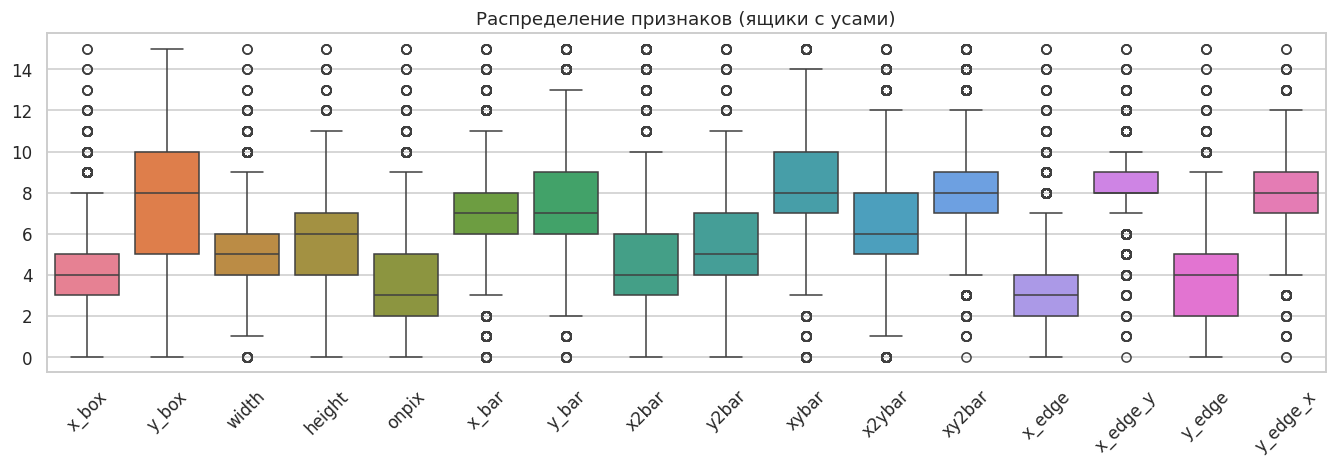

In [8]:
outliers = iqr_outlier_mask(df[FEATURES]).sum().sort_values(ascending=False)
print(outliers.to_string())
plt.figure(figsize=(15, 4))
sns.boxplot(data=df[FEATURES])
plt.xticks(rotation=45)
plt.title("Распределение признаков (ящики с усами)")
plt.show()

IQR-«выбросы» здесь — не ошибки: все значения лежат в допустимом диапазоне 0–15, а «крайние» значения характерны для отдельных букв (например, очень узкая `I` или широкая `W`). Удаление выбросов вырезало бы целые классы, поэтому оставляем их; стандартизация перед подачей в сеть сделает масштаб признаков одинаковым.

## 4. Разведочный анализ (EDA)

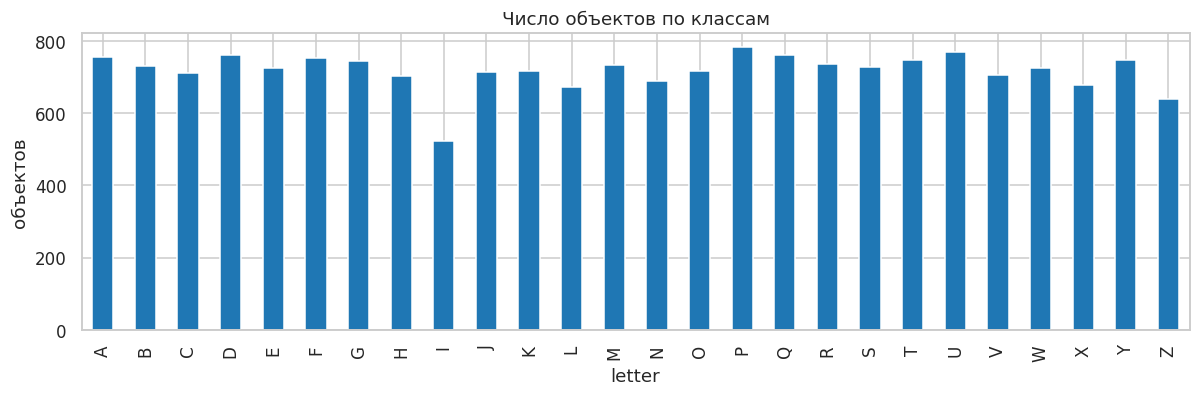

In [9]:
plt.figure(figsize=(13, 3.5))
df[TARGET].value_counts().sort_index().plot.bar(color="tab:blue")
plt.title("Число объектов по классам")
plt.ylabel("объектов")
plt.show()

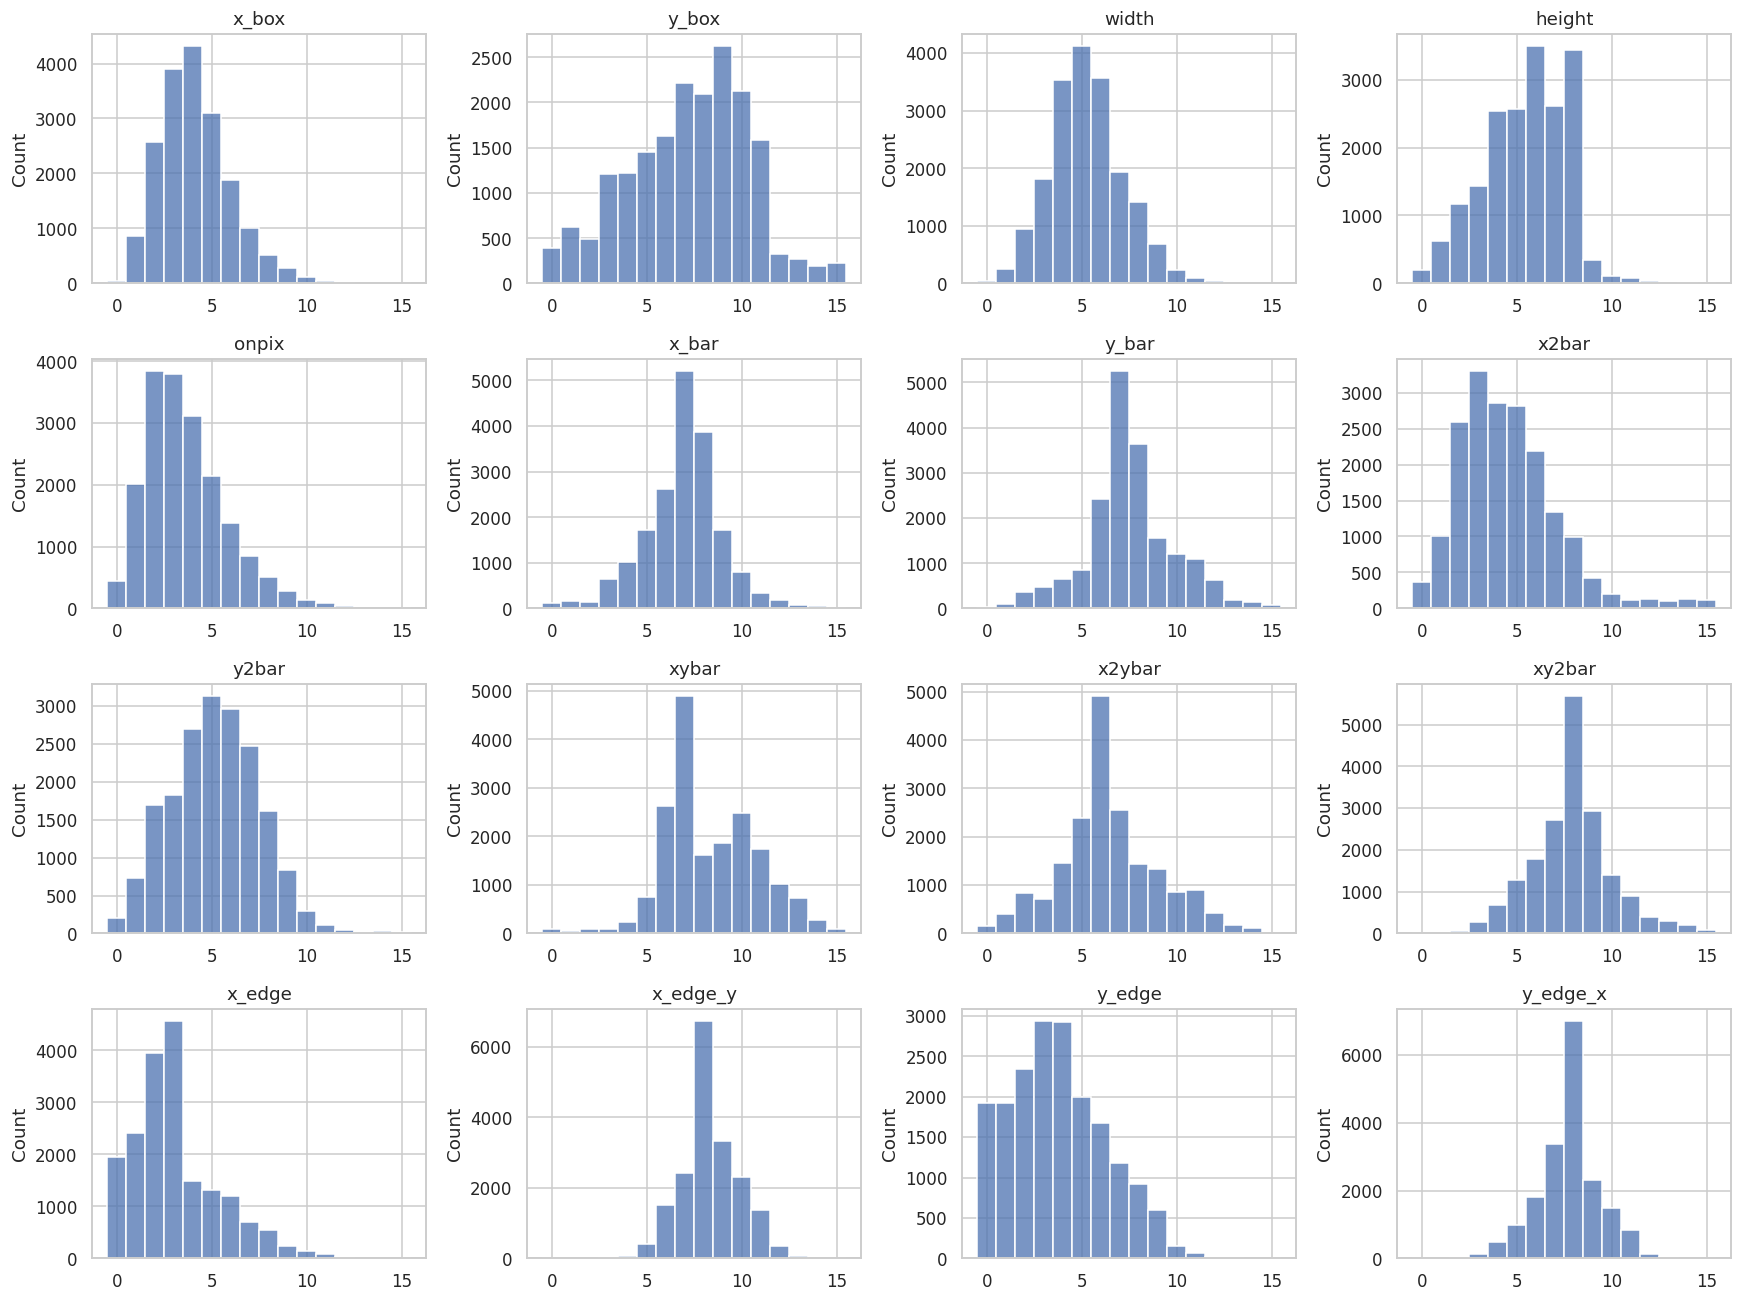

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], discrete=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

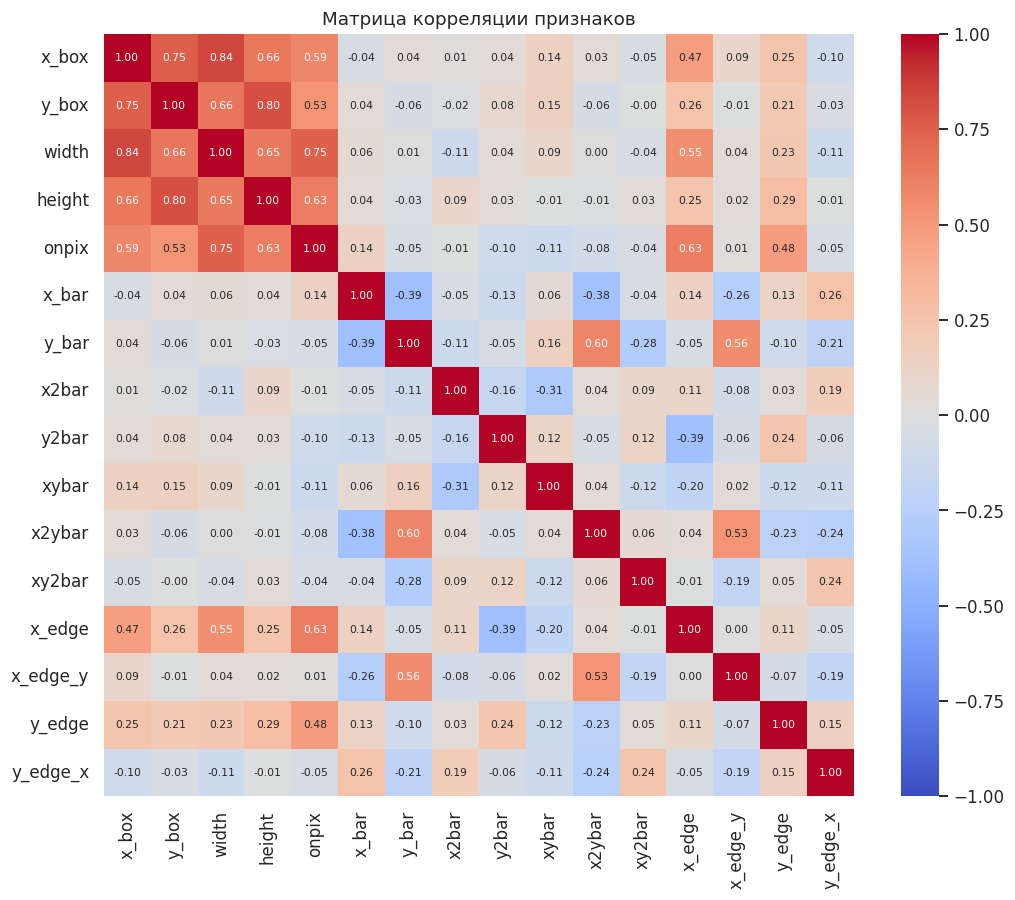

In [11]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Матрица корреляции признаков")
plt.show()

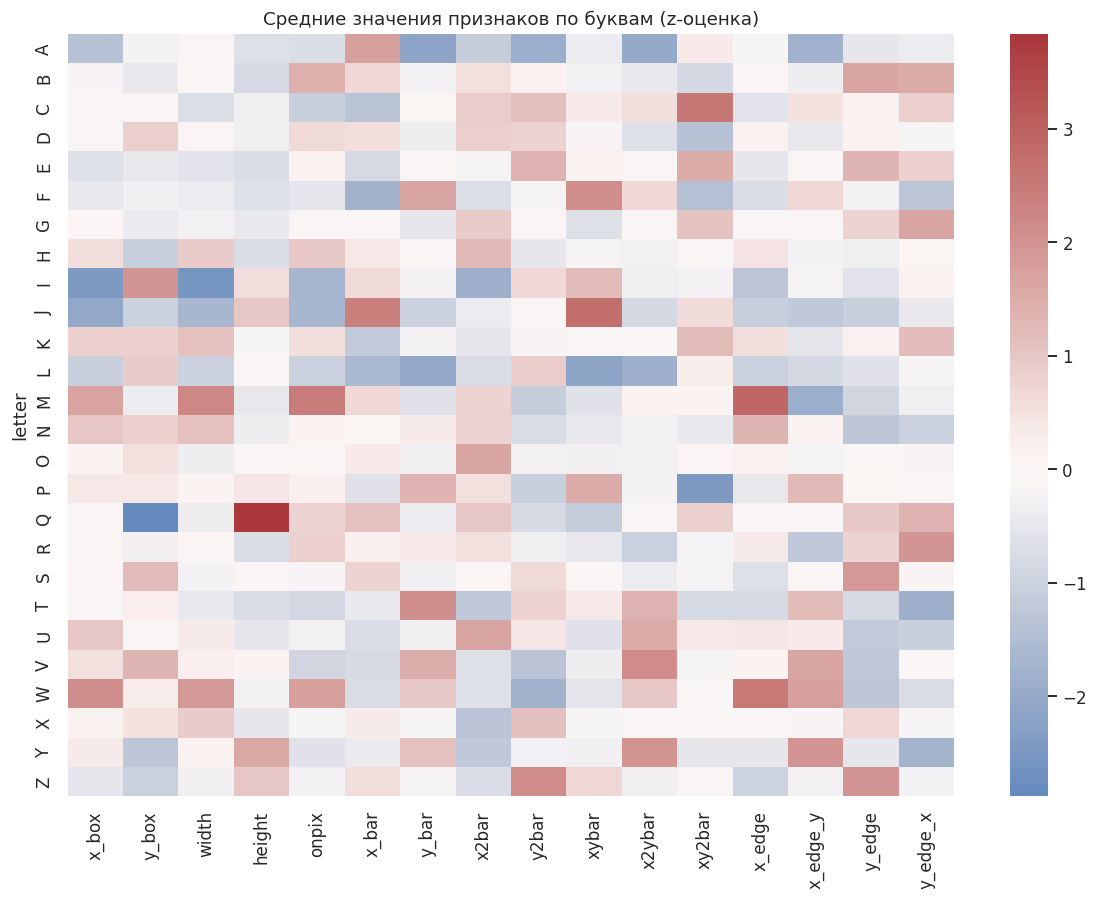

In [12]:
class_profile = df.groupby(TARGET)[FEATURES].mean()
plt.figure(figsize=(13, 9))
sns.heatmap((class_profile - class_profile.mean()) / class_profile.std(), cmap="vlag", center=0)
plt.title("Средние значения признаков по буквам (z-оценка)")
plt.show()

**Наблюдения EDA:**
- после удаления дубликатов классы примерно сбалансированы (≈ 640–780 объектов на букву); заметно меньше только у **I** (≈ 520) — у узкой буквы много одинаковых векторов признаков, поэтому среди удалённых дубликатов её особенно много;
- размерные признаки (`x_box`, `y_box`, `width`, `height`, `onpix`) сильно коррелируют между собой (0,53–0,84); заметные связи есть и между `y_bar`, `x2ybar` и `x_edge_y` (0,53–0,60);
- по тепловой карте профилей у каждой буквы свой «отпечаток» признаков, но границы между классами сложные и нелинейные — это задача для нейросети со скрытыми слоями.

## 5. Подготовка данных
- **Кодирование метки:** буквы → целые числа 0–25 (`LabelEncoder`). One-hot для цели не нужен: используем `sparse_categorical_crossentropy`, которая принимает индексы классов.
- **Масштабирование:** `StandardScaler` (среднее 0, σ = 1), обучается **только на train**. Нейросети чувствительны к масштабу входов: без нормализации градиентный спуск сходится медленнее.
- **Разбиение:** 70 / 15 / 15 со стратификацией.

In [13]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[TARGET])
X = df[FEATURES].to_numpy(dtype="float32")
class_names = list(label_encoder.classes_)

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train, X_val, X_test = (scaler.transform(part).astype("float32") for part in (X_train, X_val, X_test))
print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")

train: (13067, 16), val: (2800, 16), test: (2801, 16)


## 6. Архитектура
Полносвязная сеть: каждый нейрон слоя связан со всеми выходами предыдущего слоя.

`Input(16)` → [`Dense` + ReLU → `BatchNormalization` → `Dropout`] × N → `Dense(26)` + softmax

- **ReLU** — нелинейная активация; без нелинейности сеть любой глубины сводится к линейной модели;
- **BatchNormalization** нормирует активации внутри сети и ускоряет обучение;
- **Dropout** случайно «выключает» часть нейронов на обучении — регуляризация против переобучения;
- **softmax** на выходе превращает 26 чисел в распределение вероятностей по классам.

Сравниваем три варианта ширины/глубины сети и выбираем лучший по валидации.

In [14]:
def build_fcn(n_features, n_classes, hidden, dropout, name):
    inputs = keras.Input(shape=(n_features,), name="features")
    x = inputs
    for i, units in enumerate(hidden, start=1):
        x = layers.Dense(units, activation="relu", name=f"dense_{i}")(x)
        x = layers.BatchNormalization(name=f"bn_{i}")(x)
        x = layers.Dropout(dropout, name=f"dropout_{i}")(x)
    outputs = layers.Dense(n_classes, activation="softmax", name="probabilities")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


build_fcn(len(FEATURES), len(class_names), name="fcn_medium", **ARCHITECTURES["fcn_medium"]).summary()

Model: "fcn_medium"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,138 (164.60 KB)

 Trainable params: 41,370 (161.60 KB)

 Non-trainable params: 768 (3.00 KB)

## 7. Обучение
- **Adam** — адаптивный оптимизатор;
- **EarlyStopping** останавливает обучение, если `val_loss` не улучшается 12 эпох, и возвращает лучшие веса;
- **ReduceLROnPlateau** уменьшает шаг обучения в 2 раза при «застое».

In [15]:
results, histories, models = {}, {}, {}
for name, config in ARCHITECTURES.items():
    model = build_fcn(len(FEATURES), len(class_names), name=name, **config)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
        MlflowLogger(),
    ]
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"hidden": config["hidden"], "dropout": config["dropout"], "lr": LEARNING_RATE,
                           "batch_size": BATCH_SIZE, "n_params": model.count_params()})
        history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS,
                            batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)
        val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
        mlflow.log_metrics({"best_val_loss": val_loss, "best_val_accuracy": val_acc})
    results[name] = {"params": model.count_params(), "epochs": len(history.history["loss"]),
                     "val_loss": val_loss, "val_accuracy": val_acc}
    histories[name], models[name] = history, model
    print(f"{name}: val_accuracy = {val_acc:.4f} за {results[name]['epochs']} эпох")

pd.DataFrame(results).T

fcn_small: val_accuracy = 0.9650 за 106 эпох
fcn_medium: val_accuracy = 0.9754 за 72 эпох
fcn_wide: val_accuracy = 0.9768 за 70 эпох


,params,epochs,val_loss,val_accuracy
fcn_small,12890.0,106.0,0.101605,0.965000
fcn_medium,42138.0,72.0,0.079023,0.975357
fcn_wide,179866.0,70.0,0.068765,0.976786


Лучшая архитектура: fcn_wide


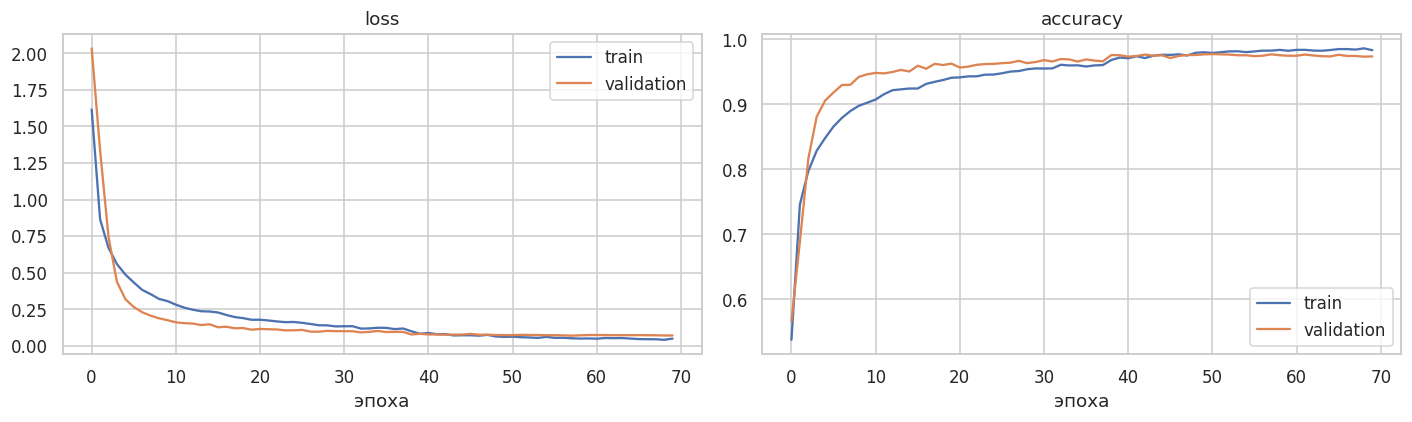

In [16]:
best_name = max(results, key=lambda n: results[n]["val_accuracy"])
best_model = models[best_name]
print(f"Лучшая архитектура: {best_name}")
history_fig = plot_history(histories[best_name], "accuracy")
plt.show()

Кривые обучения: если val-кривая потерь идёт вниз вместе с train и не расходится с ней — модель не переобучается. Небольшой разрыв нормален, его сдерживают Dropout и ранняя остановка.

## 8. Оценка на тестовой выборке

In [17]:
test_proba = best_model.predict(X_test, verbose=0)
test_pred = test_proba.argmax(axis=1)
test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "f1_macro": f1_score(y_test, test_pred, average="macro"),
}
print(classification_report(y_test, test_pred, target_names=class_names, digits=3))
pd.Series(test_metrics).round(4)

              precision    recall  f1-score   support

           A      1.000     0.982     0.991       114
           B      0.946     0.955     0.950       110
           C      0.981     0.991     0.986       106
           D      0.974     0.982     0.978       114
           E      0.945     0.945     0.945       109
           F      0.991     0.956     0.973       113
           G      0.946     0.946     0.946       112
           H      0.971     0.962     0.967       105
           I      0.987     0.949     0.967        78
           J      0.964     0.991     0.977       107
           K      0.972     0.972     0.972       107
           L      0.990     0.980     0.985       101
           M      0.991     1.000     0.995       110
           N      0.980     0.961     0.971       103
           O      0.972     0.963     0.967       108
           P      0.967     0.992     0.979       118
           Q      0.966     0.982     0.974       114
           R      0.930    

,0
accuracy,0.9743
f1_macro,0.9742


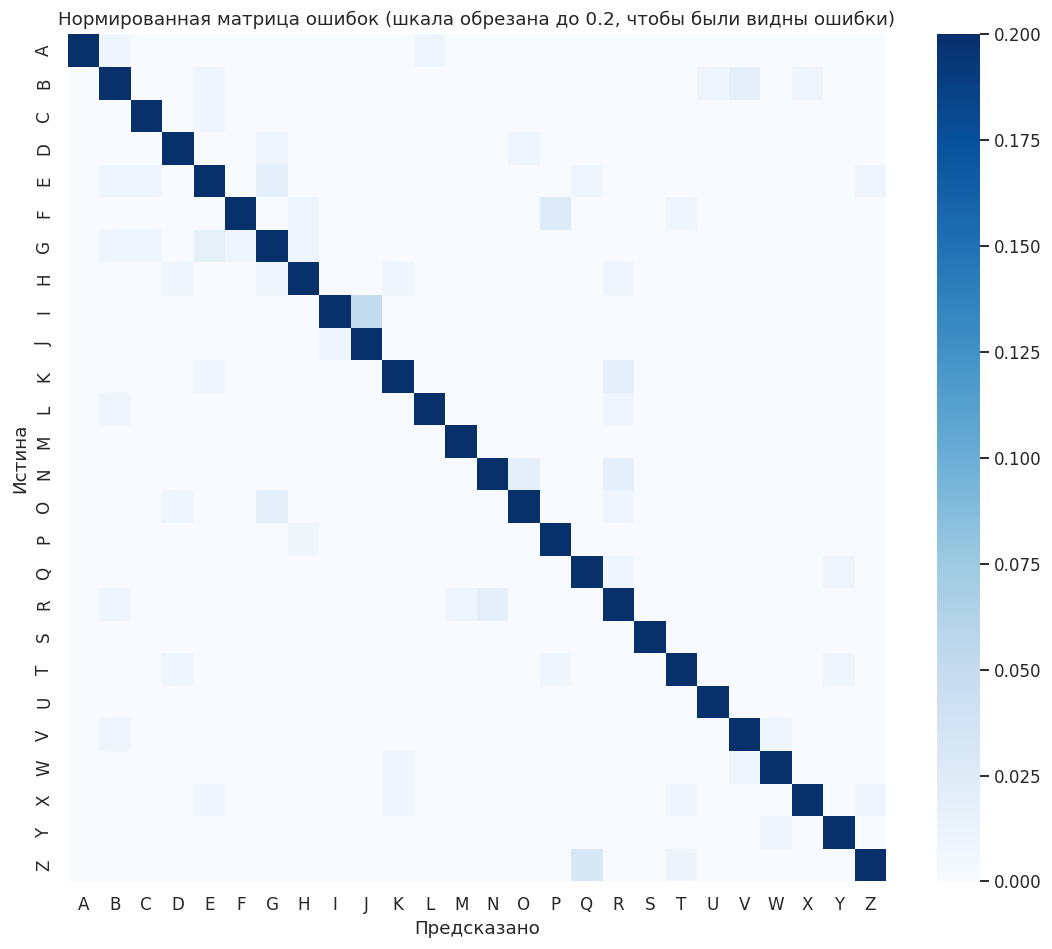

,истина,предсказано,доля
217,I,J,0.051282
666,Z,Q,0.031250
145,F,P,0.026549
352,N,O,0.019417
355,N,R,0.019417
277,K,R,0.018692
370,O,G,0.018519
110,E,G,0.018349


In [18]:
cm = confusion_matrix(y_test, test_pred, normalize="true")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, xticklabels=class_names, yticklabels=class_names, cmap="Blues", vmax=0.2, ax=ax)
ax.set(xlabel="Предсказано", ylabel="Истина", title="Нормированная матрица ошибок (шкала обрезана до 0.2, чтобы были видны ошибки)")
plt.show()

np.fill_diagonal(cm, 0)
pairs = pd.DataFrame(
    [(class_names[i], class_names[j], cm[i, j]) for i in range(len(cm)) for j in range(len(cm))],
    columns=["истина", "предсказано", "доля"],
).sort_values("доля", ascending=False).head(8)
pairs

In [19]:
with mlflow.start_run(run_name=f"{best_name}_test"):
    mlflow.log_params({"model": best_name, **{k: str(v) for k, v in ARCHITECTURES[best_name].items()}})
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig, "confusion_matrix.png")
    mlflow.log_figure(history_fig, "learning_curves.png")
print("Результаты записаны в MLflow")

Результаты записаны в MLflow


## 9. Выводы
- **Качество данных.** Из 20 000 объектов битых значений (вне диапазона 0–15), пропусков и противоречивых меток не найдено; удалено **1 332 полных дубликата** (6,7 %), осталось 18 668 объектов. IQR-выбросы (до 482 в `x_box`) оставлены — это реальные формы букв.
- **Подготовка.** Буквы закодированы в индексы 0–25, признаки стандартизированы по train, разбиение 70/15/15 со стратификацией.
- **Выбор архитектуры.** Точность на валидации: `fcn_small` (2 слоя, 12,9 тыс. параметров) — 0,965; `fcn_medium` (2 слоя, 42 тыс.) — 0,975; `fcn_wide` (3 слоя, 180 тыс.) — **0,977**. Выбрана `fcn_wide`; прирост от расширения сети уменьшается — ёмкость близка к достаточной.
- **Обучение.** Ранняя остановка сработала на 70-й эпохе. Кривые train и validation почти совпадают на протяжении всего обучения — переобучения нет, этому помогли Dropout, BatchNormalization и снижение шага обучения.
- **Итог на тесте (2 801 объект):** accuracy **0,974**, F1-macro **0,974**. Лучше всего распознаются S, U, M (F1 ≥ 0,995), хуже всего — E, G, R, B (F1 ≈ 0,945–0,95).
- **Ошибки** — между похожими по форме буквами: I → J (5 % объектов I), Z → Q (3 %), F → P (2,7 %), а также N → O, N → R, K → R (~2 %). Это логично: признаки описывают общие контуры и распределение пикселей, а у этих пар они близки.